### Myrzakassymov Azizkhan

#### Practice 1

Dataset: Coffee Shop Sales
Transaction records for Maven Roasters, a fictitious coffee shop operating out of three NYC locations. Dataset includes the transaction date, timestamp and location, along with product-level details.

Recommended Analysis

1 - How have Maven Roasters sales trended over time?

2 - Which days of the week tend to be busiest, and why do you think that's the case?

3 - Which products are sold most and least often? Which drive the most revenue for the business?

#### Data Preview
transaction_id : Unique sequential ID representing an individual transaction

transaction_date : Date of the transaction (MM/DD/YY)

transaction_time : Timestamp of the transaction (HH:MM:SS)

transaction_qty : Quantity of items sold

store_id : Unique ID of the coffee shop where the transaction took place

store_location : Location of the coffee shop where the transaction took place

product_id : Unique ID of the product sold

unit_price : Retail price of the product sold

product_category : Description of the product category

product_type : Description of the product type

product_detail : Description of the product detail


In [453]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chisquare

In [4]:
# Dataset and demonstration

df = pd.read_excel("Coffee Shop Sales.xlsx")
display(df.head()) # displaying the dataset

print(df.nunique().reset_index()) # showing all unique values in dataset

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


               index       0
0     transaction_id  149116
1   transaction_date     181
2   transaction_time   25762
3    transaction_qty       6
4           store_id       3
5     store_location       3
6         product_id      80
7         unit_price      41
8   product_category       9
9       product_type      29
10    product_detail      80


### Part 1. Aggregation

I will consider to take store location as main category (rows) and product category as subcategory (columns), looks very organic and logical, we can make analysis like "in which location which kind of food is most favorited or at least they can give a lot of money for"


##### Task 1.
Build a multi-level aggregation: group your data by two categorical attributes at once (e.g., a primary category and a secondary sub-category), and compute at least three statistics (mean, median, and a measure of spread such as std or IQR) for a numeric attribute of your choice. Present the result as a pivot table.

a. Reshape the result into a wide-format pivot table using pandas.pivot_table.

b. Flag any group with fewer than 30 observations. Explain why aggregated statistics for that group should be treated cautiously.

In [ ]:

# Pivot table

pivot = pd.pivot_table(
    df, index ='store_location', columns='product_category',
      values='unit_price', aggfunc=['mean', 'median', 'sem', 'count'] # sem - standart error of mean 
)

display(pivot)


mean                                    \
product_category    Bakery    Branded    Coffee Coffee beans   
store_location                                                 
Astoria           3.545720  19.559140  3.024235    20.356972   
Hell's Kitchen    3.569378  16.319328  3.015869    21.507083   
Lower Manhattan   3.540106  16.727794  3.031622    20.981073   

                                                                           \
product_category Drinking Chocolate Flavours Loose Tea Packaged Chocolate   
store_location                                                              
Astoria                    4.144826      0.8  9.284884           9.906455   
Hell's Kitchen             4.159713      0.8  9.198660           8.623198   
Lower Manhattan            4.141850      0.8  9.339239           8.995333   

                           median  ...       sem  count                 \
product_category       Tea Bakery  ...       Tea Bakery Branded Coffee   
store_location                     ...                                   
Astoria           2.822429    3.5  ...  0.003126   7289     279  20025   
Hell's Kitchen    2.814699    3.5  ...  0.003159   7617     119  20187   
Lower Manhattan   2.813578    3.5  ...  0.003282   7890     349  18204   

                                                                     \
product_category Coffee beans Drinking Chocolate Flavours Loose Tea   
store_location                                                        
Astoria                   502               4300     1490       344   
Hell's Kitchen            720               3763     2370       485   
Lower Manhattan           531               3405     2930       381   

                                            
product_category Packaged Chocolate    Tea  
store_location                              
Astoria                         110  16260  
Hell's Kitchen                  197  15277  
Lower Manhattan                 180  13912  

[3 rows x 36 columns]

In [121]:
used_columns = ['store_location', 'product_type', 'product_category', 'transaction_qty', 'unit_price']

As weight I will take quantity of items sold (transaction_qty)

Formula is sum of multiplication within each transactions's price and quantity of products bought, then divided by sum of weights of corresponding column:

##### Task 2.
Compute a weighted aggregation: choose a numeric attribute that should logically be weighted by another attribute (e.g., average rating weighted by number of reviews, average price weighted by sales volume). Compute both the unweighted and the weighted average per group, and quantify how much they diverge.

a. Implement the weighted mean manually (do not rely on a library that hides the formula). Show the formula in a comment.

b. For the group with the largest divergence between weighted and unweighted mean, a hypothesis for why that divergence occurs.

In [ ]:
# a.
# Implementation of Weighted Mean

def weighted_mean(df, group_cols, val_col, weight_col):
    weighted_sum = (df[val_col] * df[weight_col]).groupby([df[c] for c in group_cols]).sum() # in each transaction price multiplied by weight, then all columns is summarized and aggregated
    total_weights = df.groupby(group_cols)[weight_col].sum() # summarized weight for every column (aggregated)
    return (weighted_sum / total_weights).to_frame(name = val_col)

In [7]:
wmean = weighted_mean(
    df, 
    group_cols=['store_location', 'product_category'],
    val_col='unit_price',
    weight_col='transaction_qty',
)
mean = (
    df[['unit_price', 'store_location', 'product_category']]
    .groupby(['store_location', 'product_category'])
    .mean()
)

display(wmean)
display(mean)

unit_price
store_location  product_category              
Astoria         Bakery                3.548526
                Branded              19.559140
                Coffee                3.026279
                Coffee beans         20.356972
                Drinking Chocolate    4.146630
                Flavours              0.800000
                Loose Tea             9.284884
                Packaged Chocolate    9.906455
                Tea                   2.821020
Hell's Kitchen  Bakery                3.566938
                Branded              16.319328
                Coffee                3.018618
                Coffee beans         23.588734
                Drinking Chocolate    4.158366
                Flavours              0.800000
                Loose Tea             9.198660
                Packaged Chocolate    8.623198
                Tea                   2.815548
Lower Manhattan Bakery                3.523500
                Branded              16.423280
                Coffee                3.029294
                Coffee beans         20.953265
                Drinking Chocolate    4.139584
                Flavours              0.800000
                Loose Tea             9.339239
                Packaged Chocolate    8.995333
                Tea                   2.812310

unit_price
store_location  product_category              
Astoria         Bakery                3.545720
                Branded              19.559140
                Coffee                3.024235
                Coffee beans         20.356972
                Drinking Chocolate    4.144826
                Flavours              0.800000
                Loose Tea             9.284884
                Packaged Chocolate    9.906455
                Tea                   2.822429
Hell's Kitchen  Bakery                3.569378
                Branded              16.319328
                Coffee                3.015869
                Coffee beans         21.507083
                Drinking Chocolate    4.159713
                Flavours              0.800000
                Loose Tea             9.198660
                Packaged Chocolate    8.623198
                Tea                   2.814699
Lower Manhattan Bakery                3.540106
                Branded              16.727794
                Coffee                3.031622
                Coffee beans         20.981073
                Drinking Chocolate    4.141850
                Flavours              0.800000
                Loose Tea             9.339239
                Packaged Chocolate    8.995333
                Tea                   2.813578

In [8]:
# b
div = abs(wmean - mean)
display(div)

unit_price
store_location  product_category              
Astoria         Bakery                0.002806
                Branded               0.000000
                Coffee                0.002044
                Coffee beans          0.000000
                Drinking Chocolate    0.001805
                Flavours              0.000000
                Loose Tea             0.000000
                Packaged Chocolate    0.000000
                Tea                   0.001409
Hell's Kitchen  Bakery                0.002440
                Branded               0.000000
                Coffee                0.002749
                Coffee beans          2.081651
                Drinking Chocolate    0.001347
                Flavours              0.000000
                Loose Tea             0.000000
                Packaged Chocolate    0.000000
                Tea                   0.000850
Lower Manhattan Bakery                0.016606
                Branded               0.304513
                Coffee                0.002329
                Coffee beans          0.027809
                Drinking Chocolate    0.002266
                Flavours              0.000000
                Loose Tea             0.000000
                Packaged Chocolate    0.000000
                Tea                   0.001268

The largest divergence between mean and weighted mean is in Hell's Kitchen, coffee beans, 2,081 dollars in average. Weights are represented by quantity of unit product sold in one transaction. So there is alot of Coffee-beans being sold in one transaction in Hell's Kitchen. If we have to research this in population, then the hypothesis is:

H_0: All establishments have the same weighted average for coffee beans.

H_1: At least one establishment doesn't have same weighted average for coffee beans.


My hypothesis of why coffee beans being sold so much in Hell's Kitchen in one transaction, is that people there actually like to drink homemade coffee and have coffee machines, but yes, it's better to research by population, and see what's going on.

Might be that CV of quantity is too big and we have to eliminate all the outliers, if we have them.


##### Task 3 
Demonstrate the loss-of-variability effect of aggregation empirically: compute the coefficient of variation (CV = std / mean) of a numeric attribute at the raw (unaggregated) level, then again after aggregating to a coarser grouping. Repeat for at least two different grouping granularities (e.g., day → week → month, or store → region → country) and plot CV vs. granularity.

a. Your plot must show at least 3 points (3 levels of granularity).

b. Explain, using your actual numbers, at what point aggregation started to hide meaningful variation — not just in general terms.

In [ ]:
# CV for each
levels = { # first level of grouping is just by store location, next is by product category, and next is by product type
    'first_level': ['store_location'],
    'second_level': ['store_location', 'product_category'],
    'third_level': ['store_location', 'product_category', 'product_type']
}

cv_level = {}
for name, group_cols in levels.items():
    g = df.groupby(group_cols)['unit_price'] # we will calculate cv for unit price because it is most variate numerical column

    cv_level[name] = ( g.std() / g.mean() ).to_frame('unit_price_cv') # cv = std of level / mean of level

for cv in cv_level:
    display(cv, cv_level[cv])


'first_level'

,unit_price_cv
store_location,
Astoria,0.742495
Hell's Kitchen,0.818409
Lower Manhattan,0.795780


'second_level'

unit_price_cv
store_location  product_category                 
Astoria         Bakery                   0.103516
                Branded                  0.364098
                Coffee                   0.227235
                Coffee beans             0.414241
                Drinking Chocolate       0.123749
                Flavours                 0.000000
                Loose Tea                0.066032
                Packaged Chocolate       0.302168
                Tea                      0.141245
Hell's Kitchen  Bakery                   0.109865
                Branded                  0.364876
                Coffee                   0.225268
                Coffee beans             0.450949
                Drinking Chocolate       0.123627
                Flavours                 0.000000
                Loose Tea                0.057317
                Packaged Chocolate       0.320555
                Tea                      0.138698
Lower Manhattan Bakery                   0.118196
                Branded                  0.389369
                Coffee                   0.225178
                Coffee beans             0.411742
                Drinking Chocolate       0.122679
                Flavours                 0.000000
                Loose Tea                0.070207
                Packaged Chocolate       0.312342
                Tea                      0.137570

'third_level'

unit_price_cv
store_location  product_category   product_type                    
Astoria         Bakery             Biscotti                0.034766
                                   Pastry                  0.029979
                                   Scone                   0.146256
                Branded            Clothing                0.037506
                                   Housewares              0.214696
...                                                             ...
Lower Manhattan Packaged Chocolate Organic Chocolate       0.000000
                Tea                Brewed Black tea        0.091063
                                   Brewed Chai tea         0.180552
                                   Brewed Green tea        0.091243
                                   Brewed herbal tea       0.090910

[87 rows x 1 columns]

We can already see that CV for all levels indicates that std is WAY closer to mean in first level than in second, and same with second to third. 


for plots I will use an example of one particular product type (Brewed Green tea in Lower Manhattan) and will also calculate mean of CV for granularities

In [83]:
# preparation of data for cv to plot

# average cv per level
average_cv_per_level = {} 
for cv in cv_level:
    average_cv_per_level[cv] = cv_level[cv].mean()
average_cv_per_level = pd.DataFrame(data=average_cv_per_level).transpose()
average_cv_per_level.index.name = 'store_location'
display(average_cv_per_level)

# brewed tea per level
brewed_tea_example = pd.DataFrame( # hardcoded because of specificity, you can find data in cv_level 
    [0.795780, 0.137570, 0.091243],
    index=['first_level', 'second_level', 'third_level'],
    columns=['unit_price_cv']
)
brewed_tea_example.index.name = 'store_location'
display(brewed_tea_example)


,unit_price_cv
store_location,
first_level,0.785561
second_level,0.197064
third_level,0.104434


,unit_price_cv
store_location,
first_level,0.795780
second_level,0.137570
third_level,0.091243


                        unit_price_cv
cv_type store_location               
mean    first_level          0.785561
        second_level         0.197064
        third_level          0.104434
example first_level          0.795780
        second_level         0.137570
        third_level          0.091243


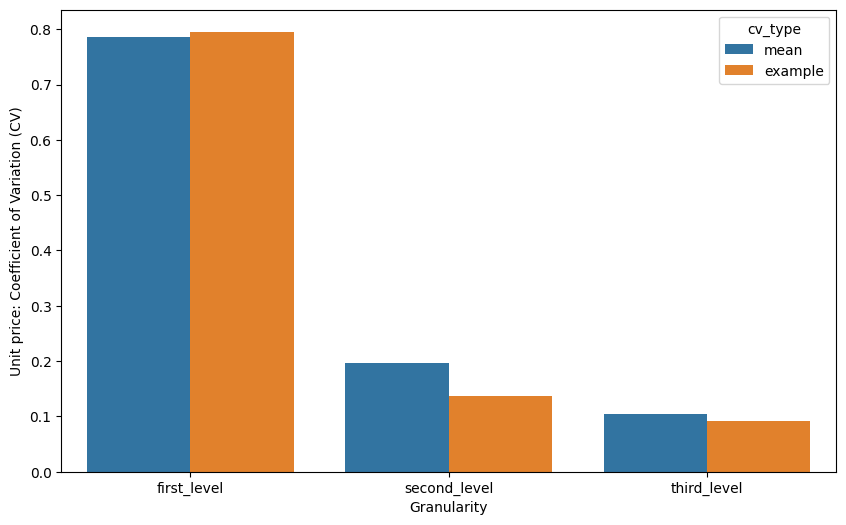

In [ ]:
# a. 
# plots 
data = pd.concat([average_cv_per_level, brewed_tea_example], keys=['mean', 'example'], names=['cv_type']) # data_preparation
print(data)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data = data,
    x = 'store_location', 
    y = 'unit_price_cv',
    hue = 'cv_type'
)

ax.set_ylabel('Unit price: Coefficient of Variation (CV)')
ax.set_xlabel('Granularity')
plt.show()

##### b. 
I think that aggregation started to hide meaningful variation already on second level of granularity, 
because if we take a look on this dataset mean and std, we can see this picture:

In [140]:
print('Second level: \n')
mean = (
    df[['unit_price', 'store_location', 'product_category']]
    .groupby(['store_location', 'product_category'])
    .mean()
)
std = (
    df[['unit_price', 'store_location', 'product_category']]
        .groupby(['store_location', 'product_category'])
        .std()
)
display(mean.loc['Hell\'s Kitchen'], std.loc['Hell\'s Kitchen'])


Second level: 



,unit_price
product_category,
Bakery,3.569378
Branded,16.319328
Coffee,3.015869
Coffee beans,21.507083
Drinking Chocolate,4.159713
Flavours,0.800000
Loose Tea,9.198660
Packaged Chocolate,8.623198
Tea,2.814699


,unit_price
product_category,
Bakery,0.392151
Branded,5.954535
Coffee,0.679379
Coffee beans,9.698587
Drinking Chocolate,0.514254
Flavours,0.000000
Loose Tea,0.527237
Packaged Chocolate,2.764208
Tea,0.390394


In [276]:
print('First level: \n')
mean = (
    df[['unit_price', 'store_location']]
    .groupby(['store_location'])
    .mean()
)
std = (
    df[['unit_price', 'store_location']]
        .groupby(['store_location'])
        .std()
)
display(mean.loc['Hell\'s Kitchen'], std.loc['Hell\'s Kitchen'])

del(mean, std)

First level: 



unit_price    3.394218
Name: Hell's Kitchen, dtype: float64

unit_price    2.777859
Name: Hell's Kitchen, dtype: float64

In first level of aggregation we had mean of 3.394218, and standart deviation is 2.777859, and in second level, for our example tea's mean 2.81 and std is 0.39; As for itself, it became more robust as a price, but If we will use it to compute average CV, then we will end up with it being less variable.

### Part 2. Sampling

##### Task 1.
Implement reservoir sampling from scratch (do not use pandas.sample or numpy.random.choice as the core mechanism) to draw a sample of size k=500 from your dataset treated as a stream (iterate row by row). Verify empirically that each row has an approximately equal probability of being selected by running your algorithm 200 times and plotting the selection-frequency distribution.


In [ ]:
def reservoir_sample(stream: pd.DataFrame | pd.Series, k, seed=None): # takes an an input dataframe or series
    rng = np.random.default_rng(seed) 
    reservoir = []

    for i in stream.index: 
        if i < k: reservoir.append(stream.loc[i]) # if i < k, just appends item that is in frame
        else: 
            random = rng.integers(0, i + 1)  # if i >= k, then it generates random index
            if random < k: reservoir[random] = stream.loc[i] # and if random is smaller than k

    sample = pd.DataFrame(data=reservoir).reset_index().drop('index', axis=1)
    return sample

In [ ]:
sample = reservoir_sample(
        stream=df,
        k=50,
    )

display(sample)
del sample

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,140077,2023-06-22,16:47:10,1,3,Astoria,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,25661,2023-02-15,09:51:22,2,3,Astoria,26,3.00,Coffee,Organic brewed coffee,Brazilian Rg
2,104247,2023-05-22,13:57:36,2,3,Astoria,50,2.50,Tea,Brewed Black tea,Earl Grey Rg
3,111329,2023-05-29,10:22:37,2,3,Astoria,26,3.00,Coffee,Organic brewed coffee,Brazilian Rg
4,102910,2023-05-21,10:07:03,1,5,Lower Manhattan,79,3.75,Bakery,Scone,Jumbo Savory Scone
5,13664,2023-01-24,17:24:16,2,3,Astoria,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
6,49949,2023-03-24,09:37:53,1,5,Lower Manhattan,70,3.25,Bakery,Scone,Cranberry Scone
7,122804,2023-06-08,14:44:57,1,3,Astoria,51,3.00,Tea,Brewed Black tea,Earl Grey Lg
8,121278,2023-06-07,10:16:22,2,8,Hell's Kitchen,52,2.50,Tea,Brewed Chai tea,Traditional Blend Chai Rg
9,89024,2023-05-09,07:46:10,1,5,Lower Manhattan,71,4.69,Bakery,Pastry,Chocolate Croissant


We can see that it works!

To emprically verify that each row has an approximately equal probability, I will try to focus on index 0, will plot its transaction_id values, sort them, and see
if plot does looks like rectangle or not as it should if its uniformly distributed.

In [261]:
list = []
for i in range (0, 200):
    sample = reservoir_sample(
        stream=df,
        k=50,
    )
    list.append(sample.loc[0].transaction_id)
    print(sample.loc[0].transaction_id)


61663
10615
9738
1838
117369
130700
49251
11302
145624
34915
49659
121924
117543
129216
77500
145242
105277
101488
29959
114807
30794
95550
13649
17096
20013
96535
33381
9808
115771
72482
59921
89838
79675
137202
117417
28231
144138
89552
82646
134491
109893
78703
94549
95641
32087
67147
139964
56610
14309
34968
148095
58839
6537
133974
10332
13824
75811
72131
94859
40612
139493
13372
23497
100690
58066
37475
134376
100772
144484
54338
95540
93247
15135
31178
64443
129129
129699
123656
114993
67565
108422
91828
52490
109957
121018
14107
15784
7861
42785
53206
129675
51660
139690
37163
132091
27019
25476
97588
30944
142297
55098
275
72500
85690
37198
69147
22657
39080
88516
82794
148319
142669
147590
23046
106930
70372
120088
126085
62946
118687
79190
78314
117245
9044
19993
55355
1
47944
129556
127764
124853
68672
116369
134046
56841
91800
79177
66715
144143
45085
16360
79083
22409
81138
47443
142220
58123
67956
38725
80717
6958
54234
6469
109555
34658
143451
111078
38010
68521
11528
5

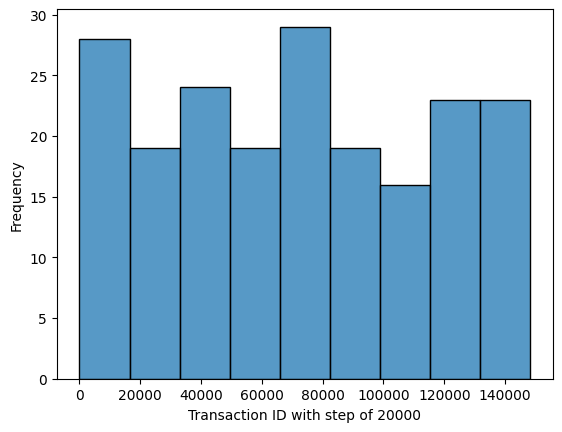

In [ ]:

list1 = pd.DataFrame(
    data=list,
    columns=['transaction_id']
)

fig, ax = plt.subplots()
sns.histplot(
    data=list1,
    x='transaction_id'
)
ax.set_ylabel('Frequency')
ax.set_xlabel('Transaction ID with step of 20000')
plt.show()

print("Number of unique elements: ", list1.nunique())
del(fig, ax, list1)

Which is equals length of our list. Looking at distribution, we see that it looks a lot like uniform, we can perform Hypothesis test, but I think just histogram is alright.

##### Task 2.
Compare three sampling strategies on the SAME target sample size (10% of the data): (a) simple random sampling, (b) stratified sampling on your class/label column, and (c) a deliberately biased 'convenience' sample (e.g., the first 10% of rows, or rows sorted by one attribute then top-10% taken). For each, compute the class-distribution divergence from the full dataset using KL divergence or chi-squared statistic, do not just eyeball the proportions.

In [ ]:
# my dataframe has 149116 rows, taking 10% and rounding it to closest value is 14912

stratified_sample = df.groupby('store_location', group_keys=False).apply(lambda x: x.sample(frac=0.1)) # stratified by store location
simple_sample = reservoir_sample(df, 14912)  # my reservoir sample is simple random sample by definition
convenience_sample = df.head(14912) 



In [394]:
display(simple_sample.head())
display(stratified_sample.head()) # it will show you only the first group, but there's actually three group with equal amount of data
display(convenience_sample.head())

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,113843,2023-05-31,15:43:39,2,3,Astoria,35,3.10,Coffee,Premium brewed coffee,Jamaican Coffee River Rg
2,98108,2023-05-17,08:09:34,3,5,Lower Manhattan,38,3.75,Coffee,Barista Espresso,Latte
3,81305,2023-05-01,17:58:46,2,5,Lower Manhattan,23,2.50,Coffee,Drip coffee,Our Old Time Diner Blend Rg
4,80460,2023-05-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
7444,7474,2023-01-14,09:23:38,1,3,Astoria,23,2.50,Coffee,Drip coffee,Our Old Time Diner Blend Rg
132588,132925,2023-06-16,17:50:09,2,3,Astoria,25,2.20,Coffee,Organic brewed coffee,Brazilian Sm
39487,39594,2023-03-09,13:08:04,1,3,Astoria,37,3.00,Coffee,Barista Espresso,Espresso shot
25669,25726,2023-02-15,10:31:01,1,3,Astoria,6,21.00,Coffee beans,Gourmet Beans,Ethiopia
12956,12986,2023-01-23,15:42:31,1,3,Astoria,41,4.25,Coffee,Barista Espresso,Cappuccino Lg


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [387]:
display(df.groupby('store_location').nunique())


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,product_id,unit_price,product_category,product_type,product_detail
store_location,,,,,,,,,,
Astoria,50599,181,11043,2,1,79,35,9,29,79
Hell's Kitchen,50735,181,11567,3,1,80,36,9,29,80
Lower Manhattan,47782,181,10244,5,1,80,41,9,29,80


Class distribution for three groups (Astoria, Hell's Kitchen, Lower Manhattan) in original Dataset is:

(50599/149116, 50735/149116, 47782/149116) 

I'll mark then as d_o

Mean and STDs are MLEs of Group Distributions.

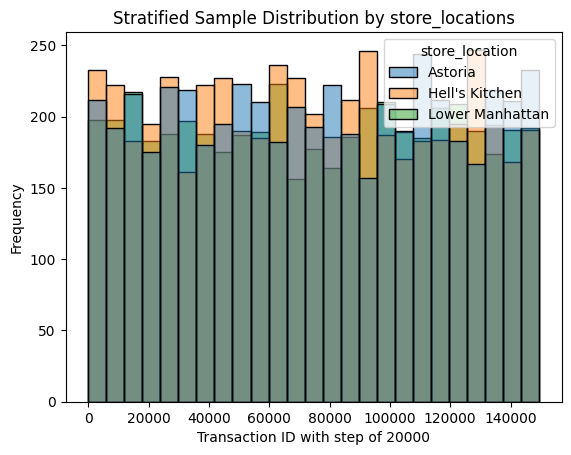

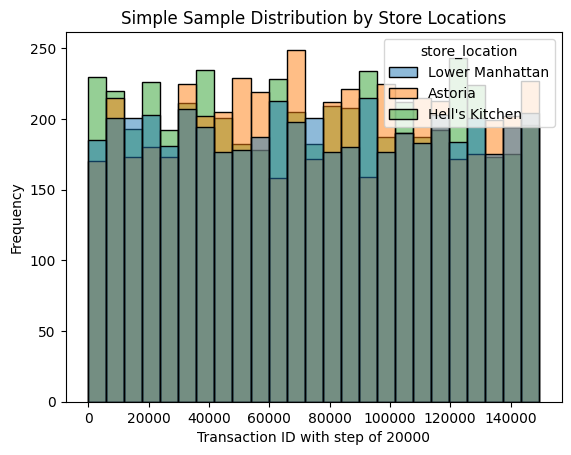

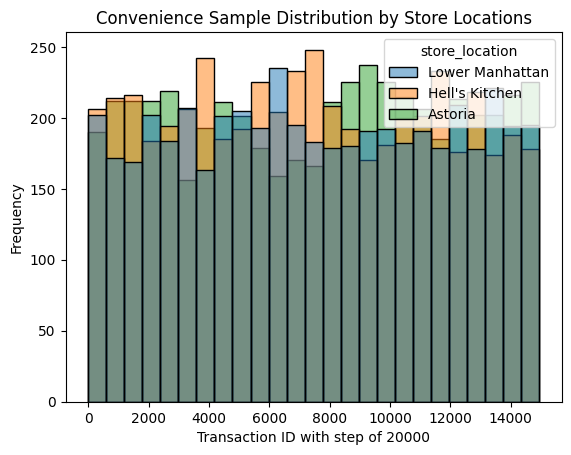

In [476]:
# Stratified Sample distribution plot
fig, ax = plt.subplots()
fig = sns.histplot(
    data=stratified_sample,
    x='transaction_id',
    hue='store_location',
)
ax.set_title('Stratified Sample Distribution by store_locations')
ax.set_ylabel('Frequency')
ax.set_xlabel('Transaction ID with step of 20000')

plt.show()
# Simple Sample Distribution plot
fig, ax = plt.subplots()
fig = sns.histplot(
    data=simple_sample,
    x='transaction_id',
    hue='store_location',
)
ax.set_title('Simple Sample Distribution by Store Locations')
ax.set_ylabel('Frequency')
ax.set_xlabel('Transaction ID with step of 20000')

plt.show()
# Convenience Sample distribution plot
fig, ax = plt.subplots()
fig = sns.histplot(
    data=convenience_sample,
    x='transaction_id',
    hue='store_location',
)
ax.set_title('Convenience Sample Distribution by Store Locations')
ax.set_ylabel('Frequency')
ax.set_xlabel('Transaction ID with step of 20000')

plt.show()

I decided not to put original dataframe distribution plot here.

I will test everything based on transaction_id attribute as the independent one

Our hypothesis statements for each of the sample will be --

H_0 : d_o = d_st, where d_o = (50599/149116, 50735/149116, 47782/149116), d_st is tuple of our sample type count of transaction quantity

H_1 : d_o != d_st

Chi Square will have 2 degrees of freedom because of 3 locations groups

In [478]:
# data preparation
d_o = (50599/149116, 50735/149116, 47782/149116) # dataframe p's as population distribution, n and p MLEs are itselves, thus we will use it as our expectancy
samples = [
    ('stratified_sample', stratified_sample), 
    ('simple_sample', simple_sample), 
    ('convenience_sample', convenience_sample)]
d_st = {}
for name, sample in samples:
    data = sample[['transaction_id', 'store_location']].groupby('store_location').nunique()
    temp = tuple(data['transaction_id'])
    d_st[name] = temp



# Chi-Square test
sample_size = 14912
for key, value in d_st.items():
    sum = 0
    expected = tuple([sample_size*x for x in d_o]) # i will multiply all elements in d_o by sample size to see what is expected value
    observed = value
    f = chisquare(observed, f_exp=expected, ddof=0, axis=0, sum_check=True, nan_policy='propagate', keepdims=False)
    print('For', key, 'the chi squared statistics is', f.statistic)
    if(f.pvalue > 0.05):
        print(f"For sample type {key} p-value is {f.pvalue}, the alpha=0.05, p-value > alpha, we do not reject null hypothesis")
    if(f.pvalue < 0.05):
        print(f"We do not reject null hypothesis for {key}")
        



For stratified_sample the chi squared statistics is 4.889211177481295e-05
For sample type stratified_sample p-value is 0.999975554242915, the alpha=0.05, p-value > alpha, we do not reject null hypothesis
For simple_sample the chi squared statistics is 1.943109775504028
For sample type simple_sample p-value is 0.37849406454300544, the alpha=0.05, p-value > alpha, we do not reject null hypothesis
For convenience_sample the chi squared statistics is 0.1878167042835927
For sample type convenience_sample p-value is 0.9103661915292854, the alpha=0.05, p-value > alpha, we do not reject null hypothesis


We can see that all of them goes through test without rejecting null hypothesis, all of them can be used,
though, simple sample has 0.37849 p-value, while convenience has 0.9103 which is interesting. May be simple sample is baddest one for proportions saving.

In [475]:
# b.
for key, value in d_st.items():
    print(key, value)
    

stratified_sample (5060, 5074, 4778)
simple_sample (4980, 5123, 4809)
convenience_sample (5042, 5068, 4802)


if we look at simple sample then we can clearly see that it has (4980, 5123, 4809) while expected value for this would be (5060, 5073, 4778) which is very close to stratified sample (5060, 5074, 4778). I think that simple sample should degrade group balances expectedly the most.

Classifiers are becoming skewed when we give them data with poorly represented group balances. 

##### Task 3.
Determine an adequate sample size empirically instead of guessing: for sample sizes n = [100,250, 500, 1000, 2500, 5000] drawn via stratified sampling, compute the mean of a key numerical attribute and a 95% confidence interval (via bootstrap resampling, 1000 iterations per n). Plothow the confidence interval width shrinks as n grows, and identify the smallest n where theinterval width drops below 5% of the full-data mean.

In [ ]:
n = [100, 250, 500]
for i in n:
    stratified_sample = df.groupby('store_location', group_keys=False).apply(lambda x: x.sample(frac=i/len(df)), include_groups=False) # stratified by store location
    mean = stratified_sample['unit_price'].mean() # unit price is key numerical attribute in my dataset
    # bootstrap here
    
    print(len(stratified_sample), mean)
    

100 3.2784999999999997
250 3.271
500 3.40952
